# PerfectPetClub – Customer Churn Dashboard

**Notebook 2 of 2** &nbsp;|&nbsp; **Owner:** Kavya Sree Bingi &nbsp;|&nbsp; **Input:** `output/customer_churn.parquet` (created by `01_ETL_Pipeline.ipynb`)

**Churn** = the customer has cancelled the auto-renew of their subscription.

**Dashboard layout**
1. **Overview:** KPI tiles, churn split, cancellations over time and churn by customer segment.
2. **Behaviour:** distributions of the engineered features for churned vs retained customers.
3. **Drivers:** correlation of each numeric feature with churn, with leakage features highlighted.
4. **Cohorts:** churn rate by sign-up month, and tenure vs engagement.

**Design choices:** one consistent colour pair used throughout (blue = retained, orange = churned, both colour-blind safe). Every churn-rate bar shows
its **sample size (n)**, because some segments are small, and has a dashed line at the **overall churn rate** for comparison.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpec

DATA_FILE = Path("output/customer_churn.parquet")
FIG_DIR = Path("output/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

RETAINED, CHURNED, GREY, INK = "#2F6DB5", "#E8743B", "#B8BEC6", "#22272E"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8A929C", "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#E6E8EB", "grid.linewidth": 0.8, "axes.axisbelow": True,
})


def load_dataset(path: Path) -> pd.DataFrame:
    """Load the ETL output and check it has what the dashboard needs."""
    if not path.exists():
        raise FileNotFoundError(f"{path} not found - run 01_ETL_Pipeline.ipynb first")
    df = pd.read_parquet(path)
    required = {"churned", "subscription_type", "tenure_days", "nps_category", "income_band", "main_device_type",
                "end_month", "start_month", "orders_per_month", "complaints_per_month", "logins_per_month"}
    missing = required - set(df.columns)
    if missing:
        raise KeyError(f"Dataset is missing columns: {sorted(missing)}")
    return df


df = load_dataset(DATA_FILE)
OVERALL = df["churned"].mean()
print(f"{len(df)} customers | {df.churned.sum()} churned | churn rate {OVERALL:.1%}")

221 customers | 86 churned | churn rate 38.9%


### Reusable chart helpers
Using functions means every panel follows the same style, and adding a new segment chart takes one line.

In [2]:
def churn_rate_by(ax, data, col, title, order=None, horizontal=False):
    """Bar chart of churn rate per category, labelled with n, with the overall churn rate as a reference line."""
    g = data.groupby(col, observed=True)["churned"].agg(rate="mean", n="size")
    if order is not None:
        g = g.reindex([o for o in order if o in g.index])
    colors = [CHURNED if r > OVERALL else RETAINED for r in g["rate"]]
    labels = g.index.astype(str)
    if horizontal:
        bars = ax.barh(labels, g["rate"], color=colors)
        ax.axvline(OVERALL, ls="--", color=INK, lw=1)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.invert_yaxis()
        ax.set_xlim(0, max(g["rate"].max() * 1.25, OVERALL * 1.25))
        for b, (r, n) in zip(bars, g.values):
            ax.text(b.get_width() + 0.01, b.get_y() + b.get_height() / 2, f"{r:.0%} (n={int(n)})", va="center", fontsize=8)
        ax.grid(axis="y", visible=False)
    else:
        bars = ax.bar(labels, g["rate"], color=colors)
        ax.axhline(OVERALL, ls="--", color=INK, lw=1)
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
        ax.set_ylim(0, max(g["rate"].max() * 1.3, OVERALL * 1.3))
        for b, (r, n) in zip(bars, g.values):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{r:.0%}\nn={int(n)}", ha="center", fontsize=8)
        ax.grid(axis="x", visible=False)
    ax.set_title(title)
    return g


def kpi_tile(ax, value, label, color=INK):
    ax.axis("off")
    ax.text(0.5, 0.58, value, ha="center", va="center", fontsize=22, fontweight="bold", color=color, transform=ax.transAxes)
    ax.text(0.5, 0.2, label, ha="center", va="center", fontsize=9, color="#5B636D", transform=ax.transAxes)
    ax.add_patch(plt.Rectangle((0.03, 0.03), 0.94, 0.94, transform=ax.transAxes, fill=False, ec="#D5D9DE", lw=1))


def compare_box(ax, data, col, title, fmt=None):
    """Side-by-side boxplots: retained vs churned."""
    groups = [data.loc[data.churned == 0, col].dropna(), data.loc[data.churned == 1, col].dropna()]
    bp = ax.boxplot(groups, tick_labels=["Retained", "Churned"], patch_artist=True, widths=0.55,
                    medianprops=dict(color=INK, lw=1.5), flierprops=dict(marker="o", ms=3, alpha=0.4))
    for patch, c in zip(bp["boxes"], [RETAINED, CHURNED]):
        patch.set_facecolor(c); patch.set_alpha(0.75)
    for i, g in enumerate(groups, start=1):
        ax.scatter(i, g.mean(), marker="D", color="white", edgecolor=INK, zorder=3, s=22)
    ax.set_title(title); ax.grid(axis="x", visible=False)
    if fmt:
        ax.yaxis.set_major_formatter(fmt)

## Figure 1: Churn overview dashboard

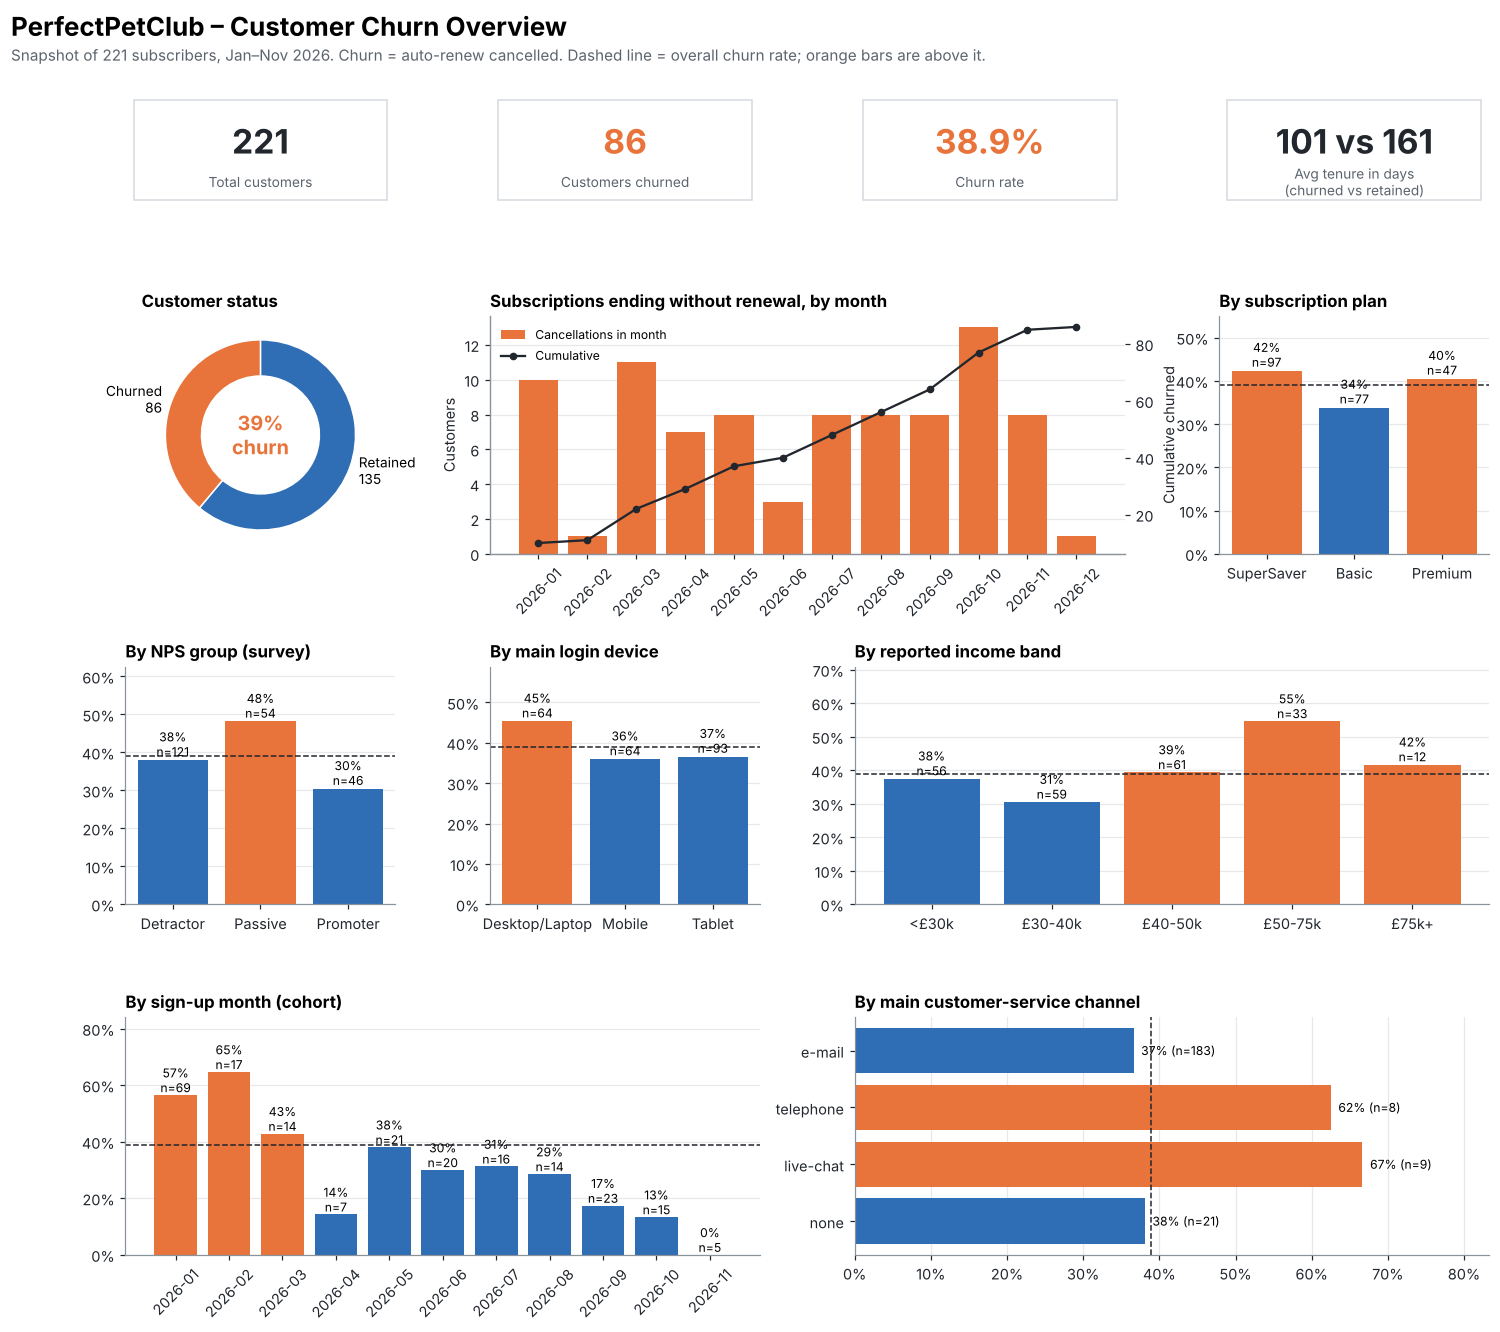

In [3]:
fig = plt.figure(figsize=(16, 13))
gs = GridSpec(4, 4, figure=fig, height_ratios=[0.45, 1, 1, 1], hspace=0.55, wspace=0.35, top=0.92)
fig.suptitle("PerfectPetClub – Customer Churn Overview", fontsize=17, fontweight="bold", x=0.06, ha="left", y=0.98)
fig.text(0.06, 0.945, f"Snapshot of {len(df)} subscribers, Jan–Nov 2026. Churn = auto-renew cancelled. "
         "Dashed line = overall churn rate; orange bars are above it.", fontsize=10, color="#5B636D")

# --- KPI row ---
ten = df.groupby("churned")["tenure_days"].mean()
kpi_tile(fig.add_subplot(gs[0, 0]), f"{len(df)}", "Total customers")
kpi_tile(fig.add_subplot(gs[0, 1]), f"{df.churned.sum()}", "Customers churned", CHURNED)
kpi_tile(fig.add_subplot(gs[0, 2]), f"{OVERALL:.1%}", "Churn rate", CHURNED)
kpi_tile(fig.add_subplot(gs[0, 3]), f"{ten[1]:.0f} vs {ten[0]:.0f}", "Avg tenure in days\n(churned vs retained)")

# --- Donut: churn split ---
ax = fig.add_subplot(gs[1, 0])
counts = df["churned"].value_counts().reindex([0, 1])
ax.pie(counts, colors=[RETAINED, CHURNED], startangle=90, counterclock=False,
       wedgeprops=dict(width=0.38, edgecolor="white"), labels=[f"Retained\n{counts[0]}", f"Churned\n{counts[1]}"],
       textprops=dict(fontsize=9))
ax.text(0, 0, f"{OVERALL:.0%}\nchurn", ha="center", va="center", fontsize=13, fontweight="bold", color=CHURNED)
ax.set_title("Customer status")

# --- Cancellations over time ---
ax = fig.add_subplot(gs[1, 1:3])
monthly = df[df.churned == 1].groupby("end_month").size()
months = sorted(set(df["start_month"]) | set(monthly.index))
monthly = monthly.reindex(months, fill_value=0)
ax.bar(monthly.index, monthly.values, color=CHURNED, label="Cancellations in month")
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly.cumsum(), color=INK, marker="o", ms=4, lw=1.5, label="Cumulative")
ax2.set_ylabel("Cumulative churned"); ax2.grid(False); ax2.spines["top"].set_visible(False)
ax.set_title("Subscriptions ending without renewal, by month"); ax.set_ylabel("Customers")
ax.tick_params(axis="x", rotation=45); ax.grid(axis="x", visible=False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False, fontsize=8)

# --- Segment churn rates ---
churn_rate_by(fig.add_subplot(gs[1, 3]), df, "subscription_type", "By subscription plan",
              order=["SuperSaver", "Basic", "Premium"])
churn_rate_by(fig.add_subplot(gs[2, 0]), df, "nps_category", "By NPS group (survey)",
              order=["Detractor", "Passive", "Promoter"])
churn_rate_by(fig.add_subplot(gs[2, 1]), df, "main_device_type", "By main login device")
churn_rate_by(fig.add_subplot(gs[2, 2:4]), df, "income_band", "By reported income band",
              order=["<£30k", "£30-40k", "£40-50k", "£50-75k", "£75k+"])
ax = fig.add_subplot(gs[3, 0:2])
churn_rate_by(ax, df, "start_month", "By sign-up month (cohort)")
ax.tick_params(axis="x", rotation=45)
churn_rate_by(fig.add_subplot(gs[3, 2:4]), df, "main_contact_platform", "By main customer-service channel",
              order=["e-mail", "telephone", "live-chat", "none"], horizontal=True)

fig.savefig(FIG_DIR / "01_churn_overview.png", bbox_inches="tight")
plt.show()

## Figure 2: Customer behaviour, churned vs retained
Boxes show the middle 50%, the line is the median and ◇ is the mean. All activity features are **per active month**, so long-standing customers do not look more engaged just because they have been around longer.

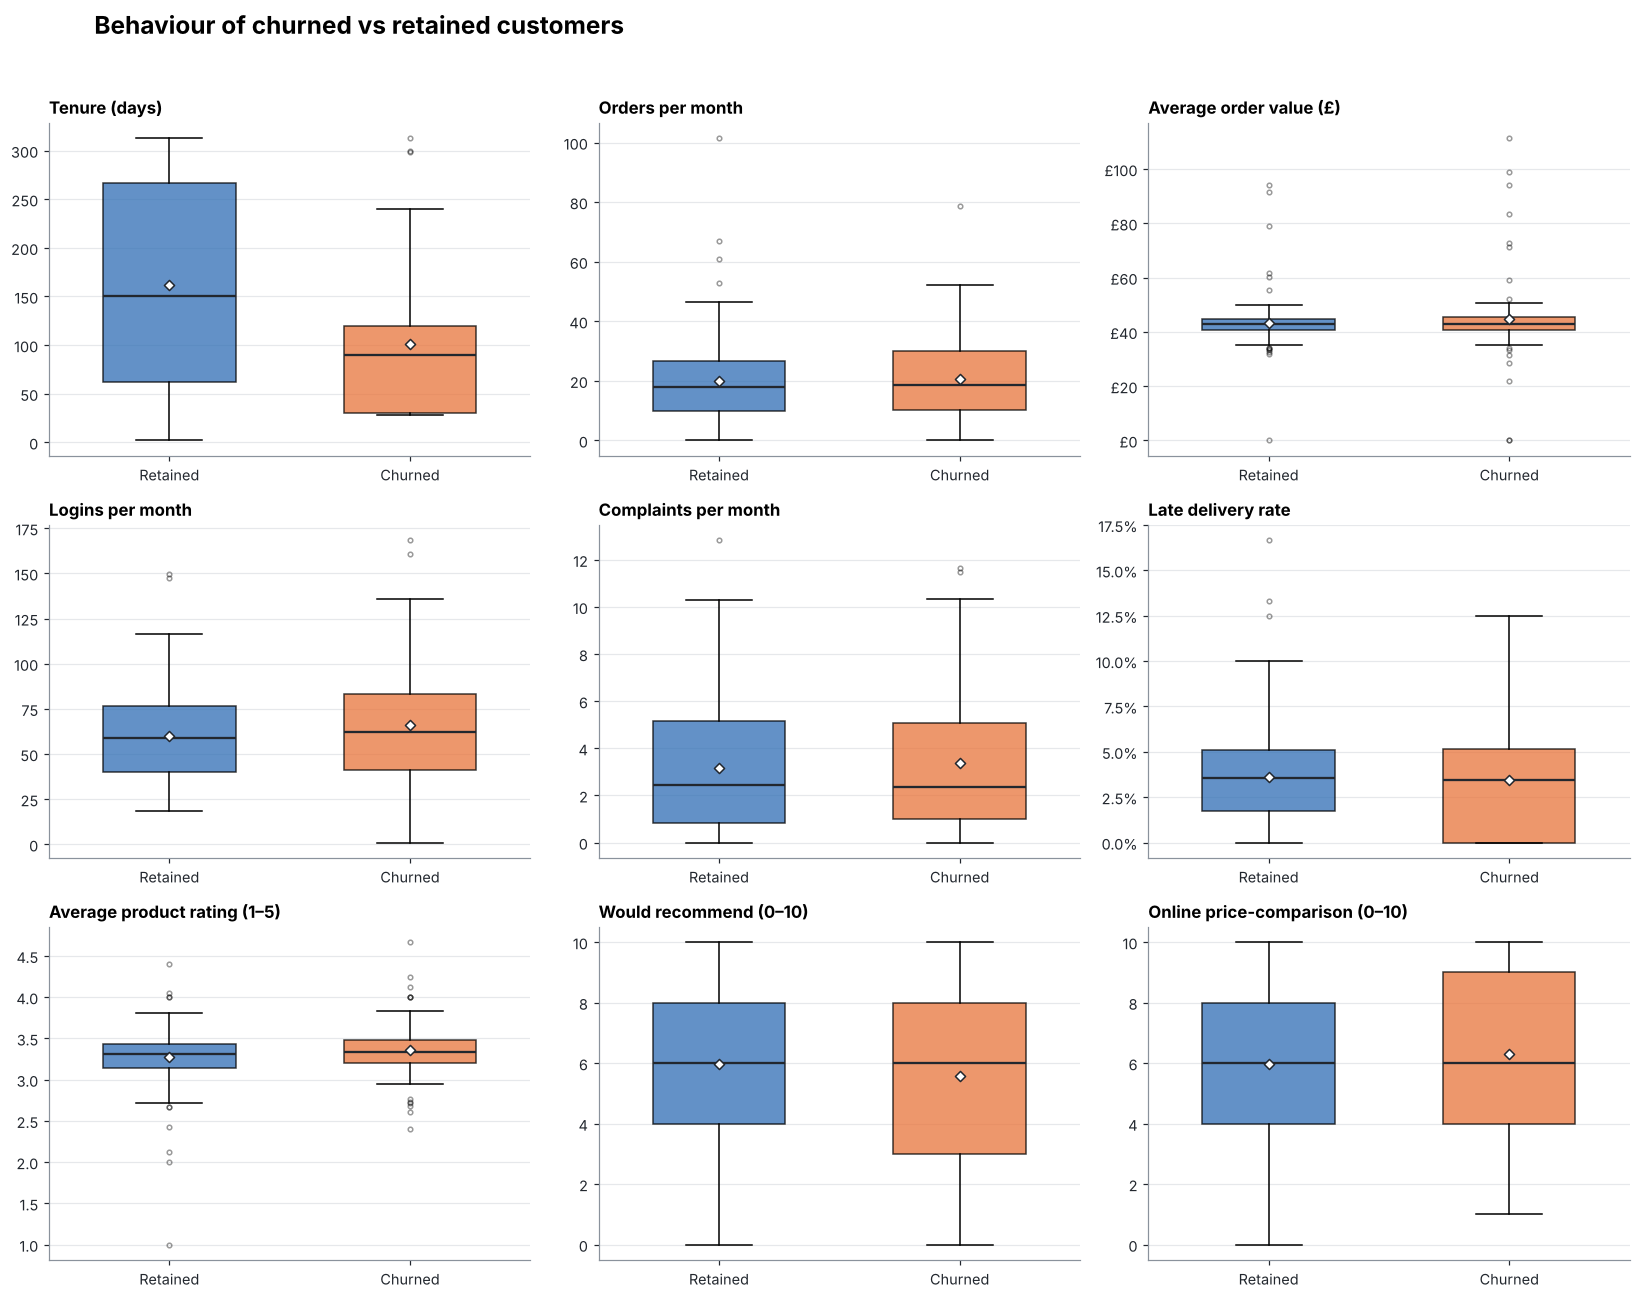

In [4]:
panels = [
    ("tenure_days", "Tenure (days)", None),
    ("orders_per_month", "Orders per month", None),
    ("avg_order_value_gbp", "Average order value (£)", mtick.StrMethodFormatter("£{x:,.0f}")),
    ("logins_per_month", "Logins per month", None),
    ("complaints_per_month", "Complaints per month", None),
    ("late_delivery_rate", "Late delivery rate", mtick.PercentFormatter(1.0)),
    ("avg_star_rating", "Average product rating (1–5)", None),
    ("nps_recommend", "Would recommend (0–10)", None),
    ("online_comparison_freq", "Online price-comparison (0–10)", None),
]
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle("Behaviour of churned vs retained customers", fontsize=16, fontweight="bold", x=0.06, ha="left")
for ax, (col, title, fmt) in zip(axes.flat, panels):
    compare_box(ax, df, col, title, fmt)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIG_DIR / "02_behaviour_boxplots.png", bbox_inches="tight")
plt.show()

## Figure 3: Which features move with churn?
Pearson correlation of each numeric feature with `churned`. The **recency** features (days since last order or login) are shown in grey: they are a *result* of churning, because customers stop ordering after cancelling, so they must not be used to predict churn (**data leakage**).

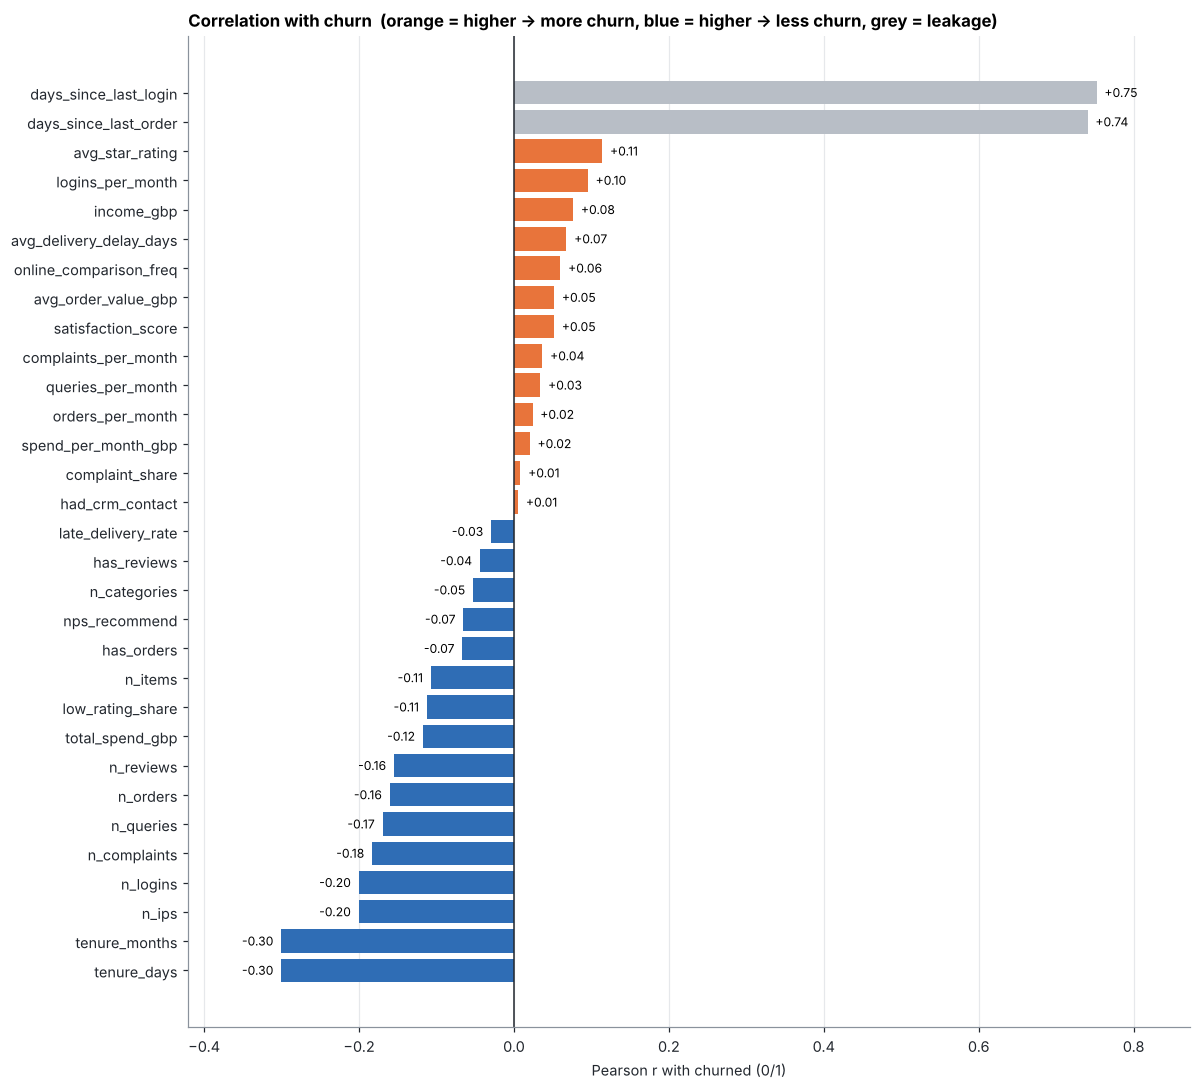

In [5]:
LEAKAGE = {"days_since_last_order", "days_since_last_login"}
num = df.select_dtypes("number").drop(columns=["customer_id", "auto_renew", "churned"])
num = num.loc[:, num.nunique() > 1]                                   # zero-variance columns have no correlation
corr = num.corrwith(df["churned"]).dropna().sort_values()

fig, ax = plt.subplots(figsize=(11, 10))
colors = [GREY if c in LEAKAGE else (CHURNED if v > 0 else RETAINED) for c, v in corr.items()]
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color=INK, lw=1)
for y, (c, v) in enumerate(corr.items()):
    ax.text(v + (0.01 if v >= 0 else -0.01), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.set_xlim(corr.min() - 0.12, corr.max() + 0.12)
ax.set_title("Correlation with churn  (orange = higher → more churn, blue = higher → less churn, grey = leakage)")
ax.set_xlabel("Pearson r with churned (0/1)"); ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_feature_correlation.png", bbox_inches="tight")
plt.show()

## Figure 4: Tenure and engagement

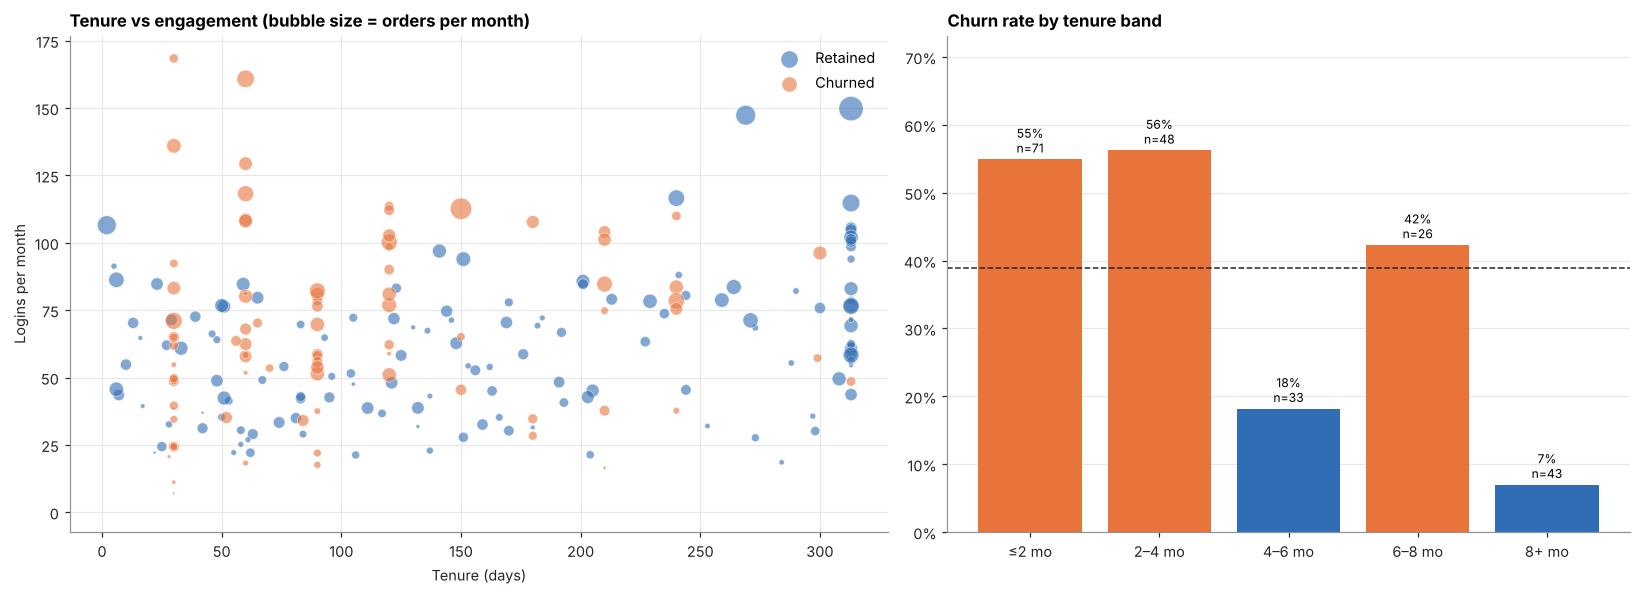

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw=dict(width_ratios=[1.2, 1]))

for flag, color, label in [(0, RETAINED, "Retained"), (1, CHURNED, "Churned")]:
    d = df[df.churned == flag]
    ax1.scatter(d["tenure_days"], d["logins_per_month"], s=d["orders_per_month"] * 2.5, color=color,
                alpha=0.6, edgecolor="white", lw=0.5, label=label)
ax1.set_xlabel("Tenure (days)"); ax1.set_ylabel("Logins per month")
ax1.set_title("Tenure vs engagement (bubble size = orders per month)")
ax1.legend(frameon=False)

# Churn rate by tenure band
bands = pd.cut(df["tenure_days"], bins=[0, 60, 120, 180, 240, 400],
               labels=["≤2 mo", "2–4 mo", "4–6 mo", "6–8 mo", "8+ mo"])
churn_rate_by(ax2, df.assign(tenure_band=bands), "tenure_band", "Churn rate by tenure band")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_tenure_engagement.png", bbox_inches="tight")
plt.show()

## Key insights (calculated from the data)

In [7]:
def rate(col, val):
    s = df.loc[df[col] == val, "churned"]
    return f"{s.mean():.0%} (n={len(s)})"

early = df[df.start_month.isin(["2026-01", "2026-02"])].churned.mean()
later = df[~df.start_month.isin(["2026-01", "2026-02"])].churned.mean()
print(f"""
1. Overall churn is {OVERALL:.1%}: {df.churned.sum()} of {len(df)} customers have cancelled auto-renew.
2. Early cohorts churn most: customers who joined in Jan–Feb churned at {early:.0%}, compared with {later:.0%} for later sign-ups.
   Note: later cohorts have had less time to cancel (right-censoring), so part of this gap is timing.
3. Survey NPS group matters: Promoters {rate('nps_category','Promoter')} vs Passives {rate('nps_category','Passive')}.
4. Plan: SuperSaver {rate('subscription_type','SuperSaver')}, Basic {rate('subscription_type','Basic')}, Premium {rate('subscription_type','Premium')}.
5. Device: Desktop/Laptop users churn at {rate('main_device_type','Desktop/Laptop')} vs Mobile {rate('main_device_type','Mobile')}.
6. Per-month activity (orders, complaints, logins, late deliveries) is very similar for both groups, so in this data
   churn is NOT explained by service problems alone.
7. Recency (days since last order/login) separates the groups almost perfectly, but this is LEAKAGE: it is a result of churn.
""")


1. Overall churn is 38.9%: 86 of 221 customers have cancelled auto-renew.
2. Early cohorts churn most: customers who joined in Jan–Feb churned at 58%, compared with 27% for later sign-ups.
   Note: later cohorts have had less time to cancel (right-censoring), so part of this gap is timing.
3. Survey NPS group matters: Promoters 30% (n=46) vs Passives 48% (n=54).
4. Plan: SuperSaver 42% (n=97), Basic 34% (n=77), Premium 40% (n=47).
5. Device: Desktop/Laptop users churn at 45% (n=64) vs Mobile 36% (n=64).
6. Per-month activity (orders, complaints, logins, late deliveries) is very similar for both groups, so in this data
   churn is NOT explained by service problems alone.
7. Recency (days since last order/login) separates the groups almost perfectly, but this is LEAKAGE: it is a result of churn.



### Limitations of this dashboard
- Small segments (e.g. live-chat n≈9, £75k+ n≈12) produce volatile rates, so always read them together with *n*.
- Correlation is not causation. Several factors are linked to tenure and cohort.
- `satisfaction_score` is not shown as a driver: its survey question duplicates the NPS question (see the ETL data quality report).
- The charts are static Matplotlib figures (as the brief requires). A future version could add interactivity (e.g. Plotly/Dash) and filters.